<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_7_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sinyal ve Görüntü İşleme Çalışması

Bu çalışma kapsamında temel sinyal üretimi, gürültü ekleme, zaman uzayında filtreleme, Ayrık Fourier Dönüşümü (DFT), frekans filtreleri ve 2-Boyutlu DFT ile görüntü işleme uygulamalarını gerçekleştireceğiz.

## Görev 1: Sinüzoidal Sinyal Üretimi ve Görselleştirilmesi

Bir sinüs dalgası matematiksel olarak şu şekilde ifade edilir:
$$y(t) = A \cdot \sin(2 \pi f t + \phi)$$
Burada:
* $A$: Genlik (Amplitude)
* $f$: Frekans (Hz)
* $\phi$: Faz (Radyan)
* $t$: Zaman vektörü

Fonksiyona parametre olarak verilecek vektör boyutu $N$ (2'nin kuvveti) ve örnekleme frekansı $f_s$ üzerinden bir zaman vektörü oluşturarak sinüs değerlerini hesaplayacağız.

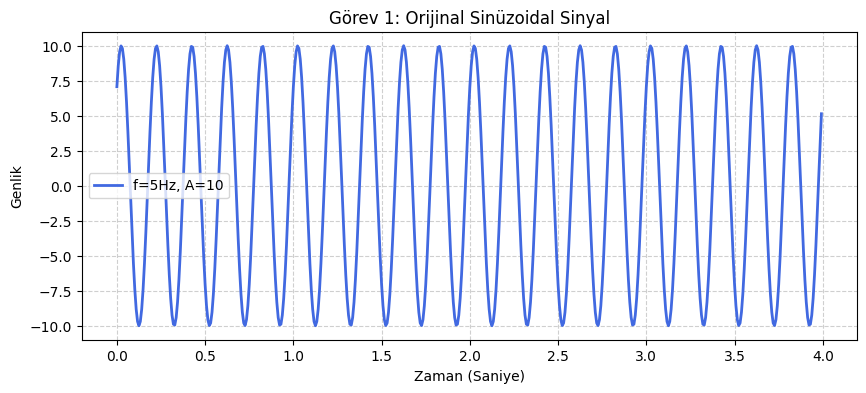

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_sine_wave(amplitude, frequency, phase, N, fs=1000):
    """
    Sinüs dalgası üretip verilen boyuttaki bir vektöre doldurur.
    N: Vektör boyutu (2'nin kuvveti olmalıdır)
    fs: Örnekleme frekansı
    """
    # N değerinin 2'nin kuvveti olup olmadığını kontrol edelim
    if (N & (N - 1) != 0) or N <= 0:
        print("Uyarı: N değeri 2'nin kuvveti değil. En yakın 2'nin kuvvetine yuvarlanabilir.")

    # Zaman vektörü oluşturma
    t = np.arange(N) / fs
    # Sinüs sinyalini hesaplama
    signal = amplitude * np.sin(2 * np.pi * frequency * t + phase)
    return t, signal

# Parametreler
N = 512 # 2^9
amp = 10
freq = 5
phase = np.pi / 4 # 45 derece
fs = 128

t, clean_signal = generate_sine_wave(amp, freq, phase, N, fs)

# Görselleştirme
plt.figure(figsize=(10, 4))
plt.plot(t, clean_signal, label=f'f={freq}Hz, A={amp}', color='royalblue', linewidth=2)
plt.title('Görev 1: Orijinal Sinüzoidal Sinyal')
plt.xlabel('Zaman (Saniye)')
plt.ylabel('Genlik')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Görev 8: Resme Gauss ve SaltAndPepper (Tuz-Biber) Gürültü Ekleme

Bu adımda, oluşturduğumuz özgün görüntüye Gauss tipi gürültü ve ani piksel değişimlerini temsil eden SaltAndPepper gürültüsü uygulayan iki fonksiyon yazacağız.

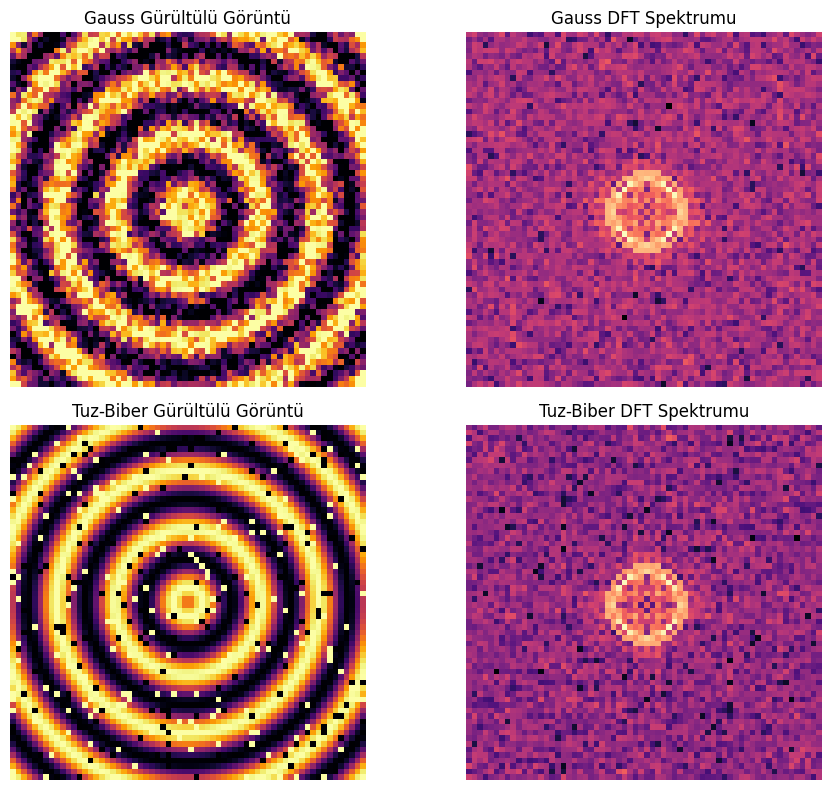

In [11]:
def add_gaussian_noise_image(image, amount):
    """
    Görüntüye belirlenen miktarda (standart sapma) Gauss gürültüsü ekler.
    """
    noise = np.random.normal(0, amount, image.shape)
    return np.clip(image + noise, -1, 1)

def add_salt_and_pepper_noise(image, noise_ratio):
    """
    Görüntüye tuz-biber gürültüsü ekler. Siyah (pepper) ve beyaz (salt) pikseller içerir.
    """
    noisy_img = image.copy()
    n_pixels = int(noise_ratio * image.size)
    # Salt
    coords_y = np.random.randint(0, image.shape[0], n_pixels // 2)
    coords_x = np.random.randint(0, image.shape[1], n_pixels // 2)
    noisy_img[coords_y, coords_x] = 1.0
    # Pepper
    coords_y = np.random.randint(0, image.shape[0], n_pixels // 2)
    coords_x = np.random.randint(0, image.shape[1], n_pixels // 2)
    noisy_img[coords_y, coords_x] = -1.0
    return noisy_img

if 'original_img' not in globals():
    img_size = 64
    x_grid, y_grid = np.meshgrid(np.linspace(-1, 1, img_size), np.linspace(-1, 1, img_size))
    original_img = np.sin(2 * np.pi * 3 * np.sqrt(x_grid**2 + y_grid**2))

gaussian_noisy_img = add_gaussian_noise_image(original_img, 0.4)
sp_noisy_img = add_salt_and_pepper_noise(original_img, 0.1)

# DFT'leri hesaplama
dft_gauss = custom_dft2d(gaussian_noisy_img)
dft_sp = custom_dft2d(sp_noisy_img)

# Görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(gaussian_noisy_img, cmap='inferno')
axes[0, 0].set_title('Gauss Gürültülü Görüntü')
axes[0, 0].axis('off')

axes[0, 1].imshow(np.log(1 + np.abs(np.fft.fftshift(dft_gauss))), cmap='magma')
axes[0, 1].set_title('Gauss DFT Spektrumu')
axes[0, 1].axis('off')

axes[1, 0].imshow(sp_noisy_img, cmap='inferno')
axes[1, 0].set_title('Tuz-Biber Gürültülü Görüntü')
axes[1, 0].axis('off')

axes[1, 1].imshow(np.log(1 + np.abs(np.fft.fftshift(dft_sp))), cmap='magma')
axes[1, 1].set_title('Tuz-Biber DFT Spektrumu')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

## Görev 9: Ters 2D-DFT (IDFT2D) ve ZMNCC Metriği ile Raporlama

ZMNCC (Zero Mean Normalized Cross Correlation), iki matrisin ortalama değerlerinden arındırılarak normalize edilmiş çarpım korelasyonudur. Değer $[ -1, 1 ]$ aralığındadır ve 1'e yakınlığı benzerliği gösterir.

$$ZMNCC = \frac{\sum_{x,y} (f(x,y) - \mu_f)(g(x,y) - \mu_g)}{\sqrt{\sum_{x,y} (f(x,y) - \mu_f)^2 \sum_{x,y} (g(x,y) - \mu_g)^2}}$$

In [12]:
def custom_idft2d(dft2d):
    """
    2D-DFT matrisinin tersini alarak görüntüyü uzay uzayına geri döndürür.
    """
    M, N = dft2d.shape
    # Satır bazında 1D-IDFT
    row_idft = np.zeros((M, N), dtype=complex)
    for r in range(M):
        n = np.arange(N)
        k = n.reshape((N, 1))
        exponent = np.exp(2j * np.pi * k * n / N)
        row_idft[r, :] = np.dot(exponent, dft2d[r, :]) / N

    # Sütun bazında 1D-IDFT
    idft2d_img = np.zeros((M, N), dtype=complex)
    for c in range(N):
        n = np.arange(M)
        k = n.reshape((M, 1))
        exponent = np.exp(2j * np.pi * k * n / M)
        idft2d_img[:, c] = np.dot(exponent, row_idft[:, c]) / M

    return np.real(idft2d_img)

def compute_zmncc(img1, img2):
    """
    İki görüntü arasındaki ZMNCC değerini hesaplar.
    """
    mean1 = np.mean(img1)
    mean2 = np.mean(img2)
    diff1 = img1 - mean1
    diff2 = img2 - mean2

    num = np.sum(diff1 * diff2)
    den = np.sqrt(np.sum(diff1**2) * np.sum(diff2**2))
    if den == 0:
        return 0
    return num / den

# Üst hücre bağımlılığını kontrol et
if 'dft_gauss' not in globals():
    if 'original_img' not in globals():
        img_size = 64
        x_grid, y_grid = np.meshgrid(np.linspace(-1, 1, img_size), np.linspace(-1, 1, img_size))
        original_img = np.sin(2 * np.pi * 3 * np.sqrt(x_grid**2 + y_grid**2))
    gaussian_noisy_img = add_gaussian_noise_image(original_img, 0.4)
    dft_gauss = custom_dft2d(gaussian_noisy_img)

# Gürültülü görüntünün doğrudan Ters DFT'si
reconstructed_gauss = custom_idft2d(dft_gauss)
zmncc_score = compute_zmncc(original_img, reconstructed_gauss)

print(f"Orijinal ve Geri Çatılan (Gauss'lu) Resim arasındaki ZMNCC: {zmncc_score:.4f}")

Orijinal ve Geri Çatılan (Gauss'lu) Resim arasındaki ZMNCC: 0.8877


### Piksel Yakınlığını Ölçebilecek Diğer Metrikler ve Kıyaslama

* **MSE (Mean Squared Error - Ortalama Kare Hata):**
  * *Avantajı:* Hesaplanması son derece kolay ve optimizasyon problemlerinde türevlenebilirdir.
  * *Dezavantajı:* İnsan görsel algısıyla uyuşmaz. Parlaklık kaymalarına karşı aşırı duyarlıdır.
* **PSNR (Peak Signal-to-Noise Ratio):**
  * *Avantajı:* Desibel (dB) ölçeğinde sinyal kalitesini gösterir. Sıkıştırma algoritmalarında standarttır.
  * *Dezavantajı:* MSE tabanlı olduğundan yapısal bozulmaları ayırt edemez.
* **SSIM (Structural Similarity Index Measure):**
  * *Avantajı:* İnsan gözünün algısal sistemine en yakın sonucu verir. Kontrast, parlaklık ve yapısal özellikleri kıyaslar.
  * *Dezavantajı:* Matematiksel olarak daha karmaşıktır.

## Görev 10: Frekans Filtreleri Tasarımı (Low-Pass, High-Pass, Band-Pass, Band-Reject)

Frekans uzayında, görüntünün merkezinden dışarıya doğru frekanslar artar.
* **Low-Pass (Alçak Geçiren):** Merkezdeki alçak frekansları geçirir, gürültüyü azaltırken resmi bulanıklaştırır.
* **High-Pass (Yüksek Geçiren):** Kenar geçişlerini ve detayları keskinleştirir, arka planı karartır.
* **Band-Pass (Bant Geçiren):** Sadece belirli bir frekans bandını korur.
* **Band-Reject (Bant Söndüren):** Belirli bir frekans bandındaki istenmeyen periyodik gürültüleri yok eder.

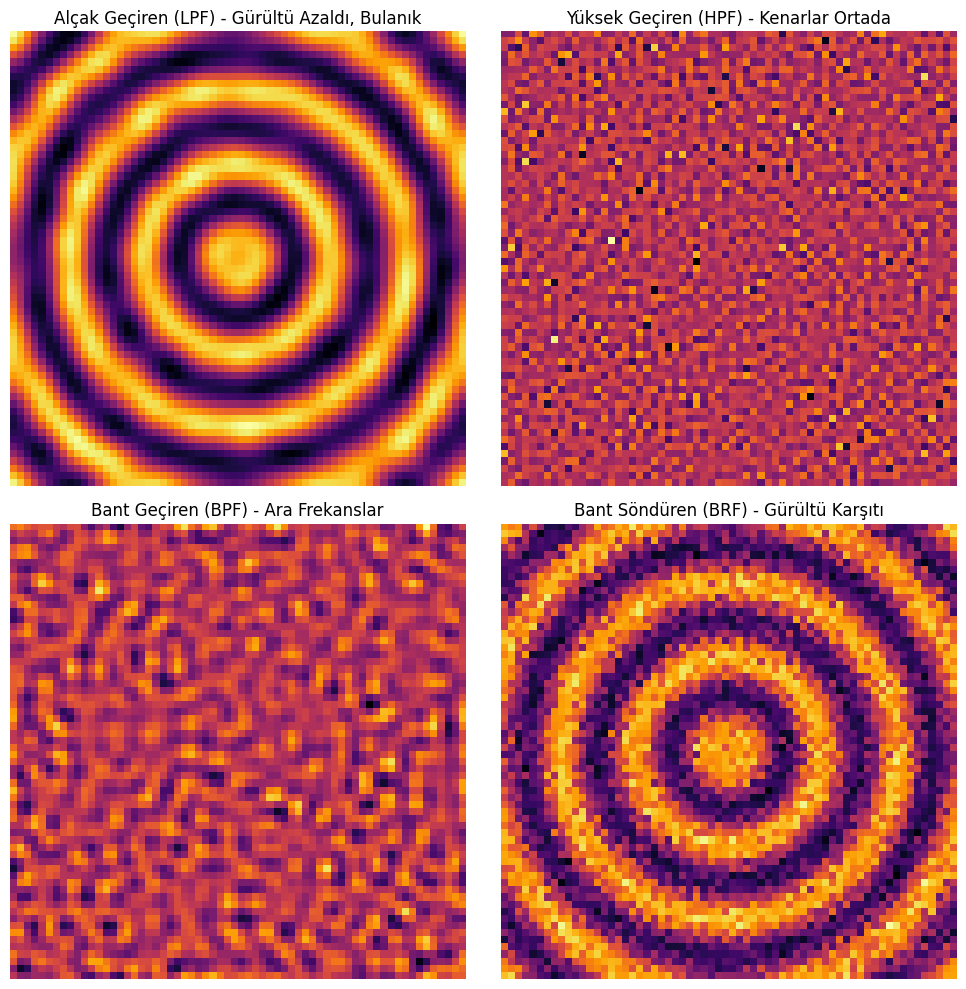

In [13]:
def create_filters(shape, cutoff_low, cutoff_high):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2

    # Mesafe matrisi oluşturma
    y, x = np.ogrid[-crow:rows-crow, -ccol:cols-ccol]
    d = np.sqrt(x*x + y*y)

    # Filtre maskeleri
    lpf = d <= cutoff_low
    hpf = d > cutoff_high
    bpf = (d >= cutoff_low) & (d <= cutoff_high)
    brf = ~bpf

    return lpf, hpf, bpf, brf

# Filtre maskelerini oluşturma (Görüntü boyutu 64x64)
lpf, hpf, bpf, brf = create_filters((64, 64), 10, 20)

# Üst hücre bağımlılığını kontrol et
if 'dft_gauss' not in globals():
    if 'original_img' not in globals():
        img_size = 64
        x_grid, y_grid = np.meshgrid(np.linspace(-1, 1, img_size), np.linspace(-1, 1, img_size))
        original_img = np.sin(2 * np.pi * 3 * np.sqrt(x_grid**2 + y_grid**2))
    gaussian_noisy_img = add_gaussian_noise_image(original_img, 0.4)
    dft_gauss = custom_dft2d(gaussian_noisy_img)

# Filtreleri Gauss gürültülü görüntünün DFT'sine uygulayalım
dft_shifted = np.fft.fftshift(dft_gauss)

img_lpf = custom_idft2d(np.fft.ifftshift(dft_shifted * lpf))
img_hpf = custom_idft2d(np.fft.ifftshift(dft_shifted * hpf))
img_bpf = custom_idft2d(np.fft.ifftshift(dft_shifted * bpf))
img_brf = custom_idft2d(np.fft.ifftshift(dft_shifted * brf))

# Filtreleme Sonuçlarının Görselleştirilmesi
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(img_lpf, cmap='inferno')
axes[0, 0].set_title('Alçak Geçiren (LPF) - Gürültü Azaldı, Bulanık')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_hpf, cmap='inferno')
axes[0, 1].set_title('Yüksek Geçiren (HPF) - Kenarlar Ortada')
axes[0, 1].axis('off')

axes[1, 0].imshow(img_bpf, cmap='inferno')
axes[1, 0].set_title('Bant Geçiren (BPF) - Ara Frekanslar')
axes[1, 0].axis('off')

axes[1, 1].imshow(img_brf, cmap='inferno')
axes[1, 1].set_title('Bant Söndüren (BRF) - Gürültü Karşıtı')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

## Görev 6: Frekans Filtresi ve IDFT (Ters DFT) ile Sinyal Yeniden Üretimi

Frekans uzayında gürültüyü temizlemenin en etkili yollarından biri, belirli bir genlik eşik değerinin (threshold) altında kalan harmonikleri sıfırlamaktır. Daha sonra Ters Ayrık Fourier Dönüşümü (IDFT) uygulayarak orijinal sinyali elde ederiz:
$$x_{filtered}[n] = \frac{1}{N} \sum_{k=0}^{N-1} X_{filtered}[k] \cdot e^{j \frac{2\pi}{N} k n}$$

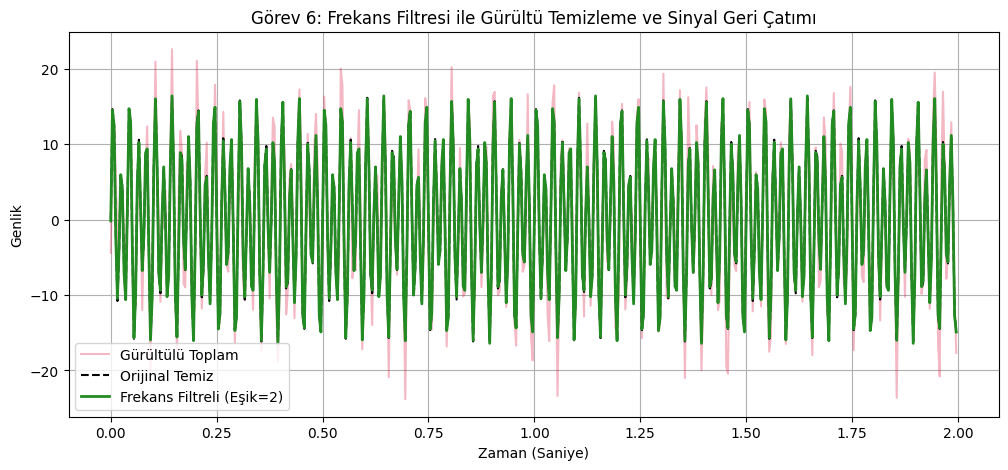

In [14]:
def custom_idft(X):
    """
    Frekans uzayındaki X kompleks spektrumunun Ters DFT'sini (IDFT) hesaplar.
    """
    N = len(X)
    n = np.arange(N)
    k = n.reshape((N, 1))
    exponent = np.exp(2j * np.pi * k * n / N)
    x = np.dot(exponent, X) / N
    return np.real(x)

def threshold_filter(signal_noisy, threshold):
    """
    Sinyalin DFT'sini alır, genliği threshold değerinin altında kalan frekans bileşenlerini sıfırlar,
    ardından IDFT ile zaman uzayına geri döner.
    """
    N = len(signal_noisy)
    X, magnitude = custom_dft(signal_noisy)

    # Eşikleme işlemi (Normalize edilmemiş genlik üzerinden)
    X_filtered = X.copy()
    X_filtered[magnitude < threshold] = 0

    # Geri çatım (IDFT)
    reconstructed = custom_idft(X_filtered)
    return reconstructed

# Hücre içi bağımlılıkları garanti altına almak adına tanımlamaları yeniliyoruz
if 's_sum_noisy' not in globals():
    fs_multi = 256
    N_multi = 512
    _, s1 = generate_sine_wave(amplitude=12, frequency=50, phase=0, N=N_multi, fs=fs_multi)
    s1_noisy = add_noise(s1, 0.25)
    _, s2 = generate_sine_wave(amplitude=5, frequency=30, phase=0, N=N_multi, fs=fs_multi)
    s2_noisy = add_noise(s2, 0.25)
    s_sum_noisy = s1_noisy + s2_noisy
    s_sum_clean = s1 + s2
else:
    s_sum_clean = s1 + s2

# Görev 5'teki toplam gürültülü sinyal için eşik filtresi uygulayalım
threshold_val = 2.0
filtered_signal = threshold_filter(s_sum_noisy, threshold_val)

# Görselleştirme
plt.figure(figsize=(12, 5))
plt.plot(t_m, s_sum_noisy, color='crimson', alpha=0.3, label='Gürültülü Toplam')
plt.plot(t_m, s_sum_clean, color='black', linestyle='--', label='Orijinal Temiz')
plt.plot(t_m, filtered_signal, color='forestgreen', linewidth=2, label='Frekans Filtreli (Eşik=2)')
plt.title('Görev 6: Frekans Filtresi ile Gürültü Temizleme ve Sinyal Geri Çatımı')
plt.xlabel('Zaman (Saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()
plt.show()

## Görev 7: 2-Boyutlu DFT (2D-DFT) Fonksiyonu

2D-DFT, görüntü gibi iki boyutlu matrislerin frekans bileşenlerini elde etmek amacıyla kullanılır. Matematiksel tanımı şöyledir:
$$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \left( \frac{ux}{M} + \frac{vy}{N} \right)}$$

Hesaplama kolaylığı açısından, satırlara 1D-DFT uygulayıp ardından elde edilen sonucun sütunlarına tekrar 1D-DFT uygulayarak (Separability Özelliği) 2D-DFT hesaplanabilir.

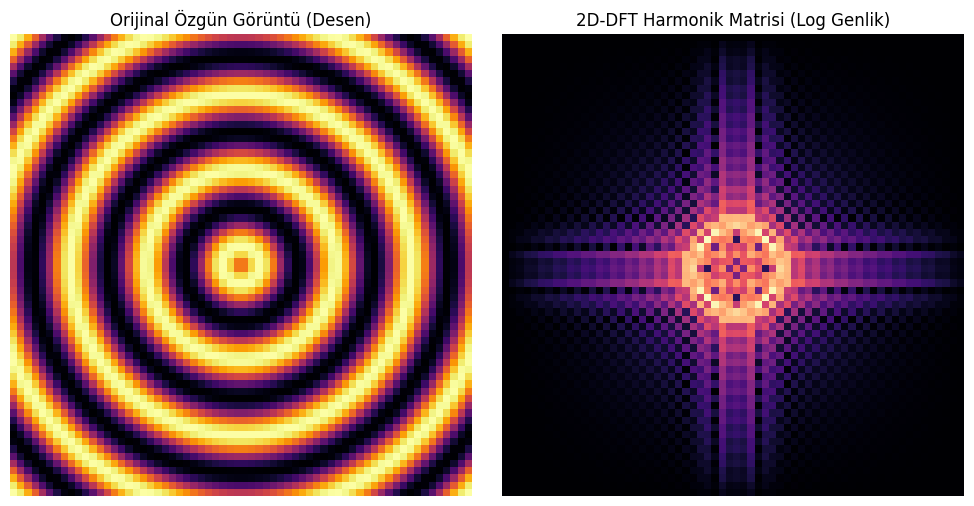

In [15]:
def custom_dft2d(image):
    """
    2 boyutlu görüntünün 2D-DFT matrisini satır-sütun ayrılabilirliği kullanarak hesaplar.
    """
    M, N = image.shape
    # Satır bazında 1D-DFT
    row_dft = np.zeros((M, N), dtype=complex)
    for r in range(M):
        row_dft[r, :], _ = custom_dft(image[r, :])

    # Sütun bazında 1D-DFT
    dft2d = np.zeros((M, N), dtype=complex)
    for c in range(N):
        dft2d[:, c], _ = custom_dft(row_dft[:, c])

    return dft2d

# Test amaçlı basit, eşsiz geometrik desenlerden bir görüntü oluşturalım
# 64x64 çözünürlükte (hesaplama hızı için 2'nin kuvveti olarak seçilmiştir)
img_size = 64
x_grid, y_grid = np.meshgrid(np.linspace(-1, 1, img_size), np.linspace(-1, 1, img_size))
# Eşsiz dairesel halka deseni
original_img = np.sin(2 * np.pi * 3 * np.sqrt(x_grid**2 + y_grid**2))

# 2D DFT hesaplama
img_dft = custom_dft2d(original_img)
# Frekans merkezini ortalamak için shift uygulayalım
img_dft_shifted = np.fft.fftshift(img_dft)
magnitude_spectrum = np.log(1 + np.abs(img_dft_shifted))

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original_img, cmap='inferno')
axes[0].set_title('Orijinal Özgün Görüntü (Desen)')
axes[0].axis('off')

axes[1].imshow(magnitude_spectrum, cmap='magma')
axes[1].set_title('2D-DFT Harmonik Matrisi (Log Genlik)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Görev 2: Sinyale Gürültü Ekleme

Gerçek dünya senaryolarında sinyaller her zaman gürültü içerir. Bu görevde, sinyalin maksimum genliği ve belirlenen gürültü oranı $[0, 1]$ doğrultusunda rastgele Gauss gürültüsü üreterek sinyale ekleyeceğiz.

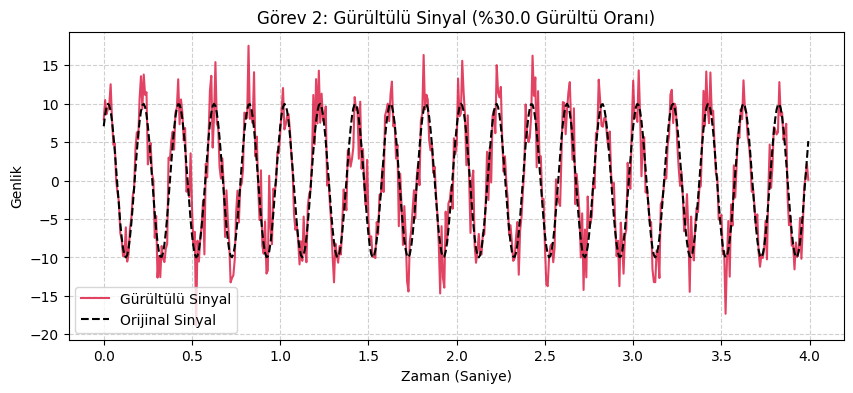

In [2]:
def add_noise(signal, noise_rate):
    """
    Sinyale genlik ve gürültü oranına bağlı olarak rastgele gürültü ekler.
    noise_rate: [0, 1] arasında gürültü oranı
    """
    max_amp = np.max(np.abs(signal))
    # Gürültü standart sapması genlik ve gürültü oranına göre belirlenir
    noise_std = max_amp * noise_rate
    noise = np.random.normal(0, noise_std, size=len(signal))
    noisy_signal = signal + noise
    return noisy_signal

noise_ratio = 0.3
noisy_signal = add_noise(clean_signal, noise_ratio)

# Görselleştirme
plt.figure(figsize=(10, 4))
plt.plot(t, noisy_signal, label='Gürültülü Sinyal', color='crimson', alpha=0.8)
plt.plot(t, clean_signal, label='Orijinal Sinyal', color='black', linestyle='--', linewidth=1.5)
plt.title(f'Görev 2: Gürültülü Sinyal (%{noise_ratio*100} Gürültü Oranı)')
plt.xlabel('Zaman (Saniye)')
plt.ylabel('Genlik')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Görev 3: Gauss ve Medyan Filtreleri ile Sinyal Temizleme

* **Gauss Filtresi (Doğrusal Filtre):** Belirli bir pencere boyutundaki değerlerin ağırlıklı ortalamasını alarak yüksek frekanslı gürültüleri yumuşatır.
* **Medyan Filtresi (Doğrusal Olmayan Filtre):** Penceredeki değerleri sıralayıp ortadaki değeri seçer. Özellikle ani sıçramalar ve tuz-biber gürültülerinde etkilidir.

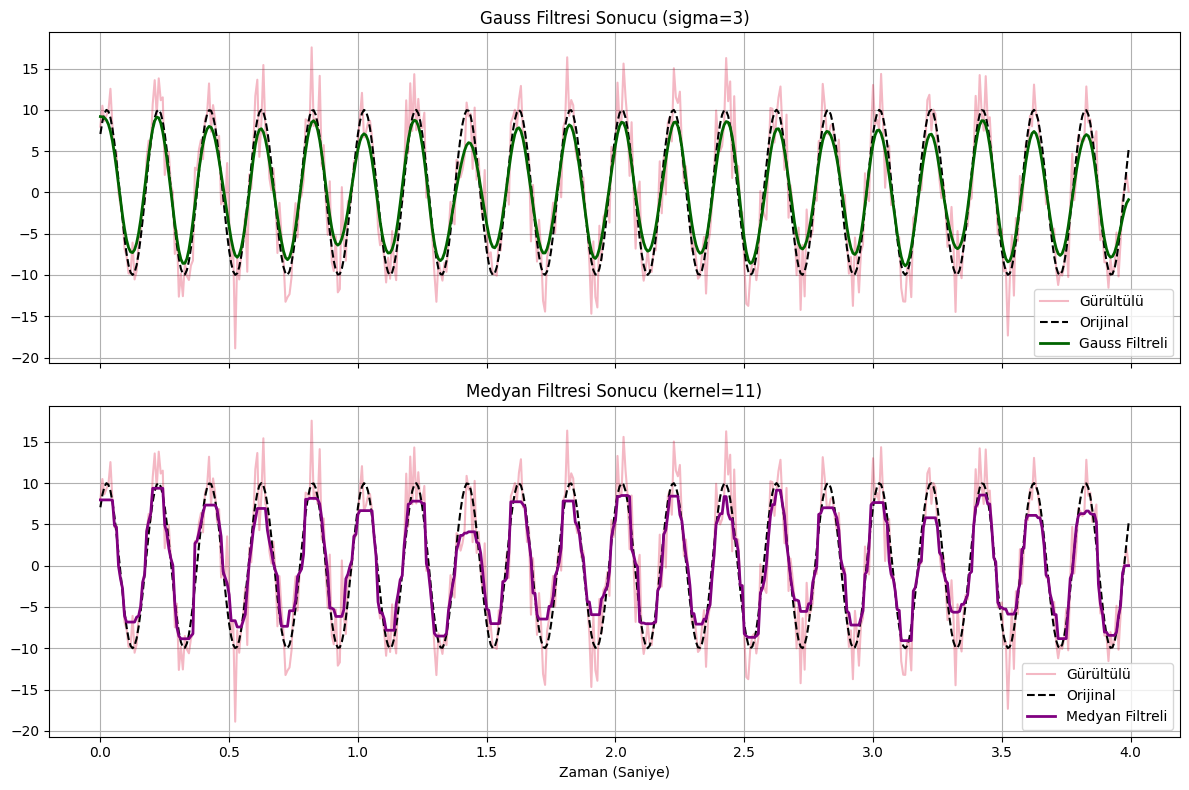

In [3]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt

# Gauss Filtresi Uygulama (sigma parametresi yumuşatma derecesini belirler)
gaussian_filtered = gaussian_filter1d(noisy_signal, sigma=3)

# Medyan Filtresi Uygulama (kernel_size tek sayı olmalıdır)
median_filtered = medfilt(noisy_signal, kernel_size=11)

# Sonuçların Karşılaştırılması
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Gauss Sonucu
axes[0].plot(t, noisy_signal, color='crimson', alpha=0.3, label='Gürültülü')
axes[0].plot(t, clean_signal, color='black', linestyle='--', label='Orijinal')
axes[0].plot(t, gaussian_filtered, color='darkgreen', linewidth=2, label='Gauss Filtreli')
axes[0].set_title('Gauss Filtresi Sonucu (sigma=3)')
axes[0].grid(True)
axes[0].legend()

# Medyan Sonucu
axes[1].plot(t, noisy_signal, color='crimson', alpha=0.3, label='Gürültülü')
axes[1].plot(t, clean_signal, color='black', linestyle='--', label='Orijinal')
axes[1].plot(t, median_filtered, color='purple', linewidth=2, label='Medyan Filtreli')
axes[1].set_title('Medyan Filtresi Sonucu (kernel=11)')
axes[1].grid(True)
axes[1].legend()

plt.xlabel('Zaman (Saniye)')
plt.tight_layout()
plt.show()

## Görev 4: DFT (Ayrık Fourier Dönüşümü) Fonksiyonu ve Analizi

Bir $x[n]$ dizisinin $N$-noktalı DFT'si matematiksel olarak şu şekilde tanımlanır:
$$X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j \frac{2\pi}{N} k n}$$

Bu dönüşüm, zaman uzayındaki sinyalimizi frekans uzayına taşır. Elde edilen kompleks sayıların genliği (harmonikler), sinyal içerisinde hangi frekans bileşenlerinin ne kadar güçlü yer aldığını gösterir.

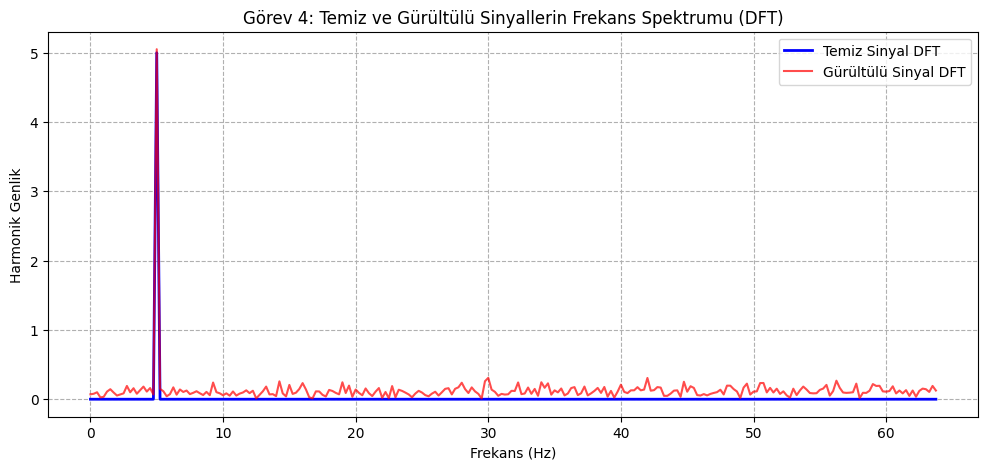

In [9]:
def custom_dft(x):
    """
    Girdi olarak verilen x vektörünün DFT'sini hesaplar ve harmonik genliklerini döndürür.
    """
    N = len(x)
    n = np.arange(N)
    k = n.reshape((N, 1))

    # Üstel üs matrisi (N x N)
    exponent = np.exp(-2j * np.pi * k * n / N)

    # DFT hesabı
    X = np.dot(exponent, x)

    # Harmonik vektörü (genlik spektrumu, simetrik olduğu için ilk yarısı yeterlidir)
    magnitude = np.abs(X) / N
    return X, magnitude

# Temiz ve gürültülü sinyaller için DFT hesaplayalım
_, clean_harmonics = custom_dft(clean_signal)
_, noisy_harmonics = custom_dft(noisy_signal)

# Frekans eksenini oluşturma
freqs = np.arange(N) * (fs / N)

# Görselleştirme
plt.figure(figsize=(12, 5))
plt.plot(freqs[:N//2], clean_harmonics[:N//2], label='Temiz Sinyal DFT', color='blue', linewidth=2)
plt.plot(freqs[:N//2], noisy_harmonics[:N//2], label='Gürültülü Sinyal DFT', color='red', alpha=0.7)
plt.title('Görev 4: Temiz ve Gürültülü Sinyallerin Frekans Spektrumu (DFT)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Harmonik Genlik')
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

## Görev 5: Çoklu Sinyal Analizi ve Sinyal Toplama

Bu görevde:
1. Frekansı 50 Hz, genliği 12 olan birinci sinyali (ve gürültüsünü),
2. Frekansı 30 Hz, genliği 5 olan ikinci sinyali (ve gürültüsünü),
3. Bu iki gürültülü sinyalin toplamını oluşturup analiz edeceğiz.

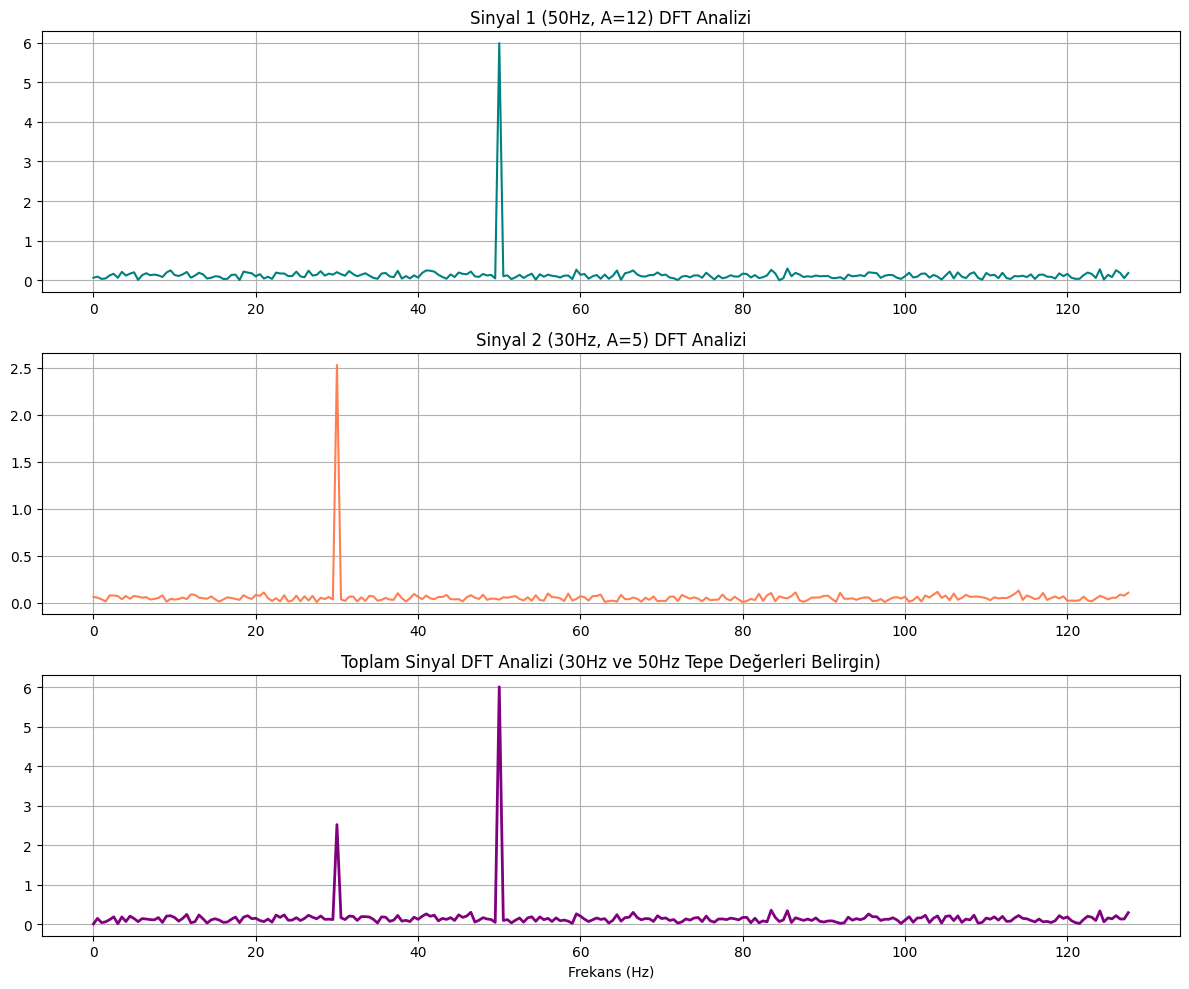

In [10]:
fs_multi = 256
N_multi = 512

# Sinyal 1: f=50Hz, A=12
t_m, s1 = generate_sine_wave(amplitude=12, frequency=50, phase=0, N=N_multi, fs=fs_multi)
s1_noisy = add_noise(s1, 0.25)

# Sinyal 2: f=30Hz, A=5
_, s2 = generate_sine_wave(amplitude=5, frequency=30, phase=0, N=N_multi, fs=fs_multi)
s2_noisy = add_noise(s2, 0.25)

# Sinyallerin Toplamı
s_sum_noisy = s1_noisy + s2_noisy

# DFT Analizleri
_, s1_dft = custom_dft(s1_noisy)
_, s2_dft = custom_dft(s2_noisy)
_, sum_dft = custom_dft(s_sum_noisy)

freqs_m = np.arange(N_multi) * (fs_multi / N_multi)
half_idx = N_multi // 2

# Görselleştirme
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(freqs_m[:half_idx], s1_dft[:half_idx], color='teal')
axes[0].set_title('Sinyal 1 (50Hz, A=12) DFT Analizi')
axes[0].grid(True)

axes[1].plot(freqs_m[:half_idx], s2_dft[:half_idx], color='coral')
axes[1].set_title('Sinyal 2 (30Hz, A=5) DFT Analizi')
axes[1].grid(True)

axes[2].plot(freqs_m[:half_idx], sum_dft[:half_idx], color='purple', linewidth=2)
axes[2].set_title('Toplam Sinyal DFT Analizi (30Hz ve 50Hz Tepe Değerleri Belirgin)')
axes[2].grid(True)

plt.xlabel('Frekans (Hz)')
plt.tight_layout()
plt.show()